<div style="background-color:#003366; color:white; padding:16px; font-size:24px; font-weight:bold; border-radius:10px; text-align:center;">
  (c) Quantum Error Correction (QEC) Encoding Schemes
</div>

<p style="font-size:20px; margin-top:12px; margin-left:10px;">
Quantum Error Correction (QEC) encoding schemes protect quantum information from noise, decoherence, and gate imperfections. These schemes encode logical qubits into physical qubits to detect and correct errors without collapsing the quantum state.
</p>

<!-- 1 -->
<div style="background-color:#ffe6e6; color:#990000; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">1. Shor Encoding</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> First QEC code designed to correct any arbitrary single-qubit error (bit flip + phase flip).</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Demonstrated the principle of QEC by combining repetition and Hadamard gates.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires 9 qubits per logical qubit – large overhead.</p>


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Shor Encoding: 9-qubit conceptual code
qc_shor = QuantumCircuit(9, 9)
# Assume qubit 0 is the logical qubit.
# First, copy the state in a bit-flip code:
qc_shor.cx(0, 1)
qc_shor.cx(0, 2)
# Now replicate each block to protect against phase-flip:
qc_shor.cx(0, 3)
qc_shor.cx(0, 6)
qc_shor.cx(1, 4)
qc_shor.cx(1, 7)
qc_shor.cx(2, 5)
qc_shor.cx(2, 8)

# Add measurements for visualization.
qc_shor.measure(range(9), range(9))

# Run the circuit on the qasm simulator
backend = Aer.get_backend('qasm_simulator')
tqc_shor = transpile(qc_shor, backend)
job_shor = backend.run(tqc_shor, shots=1024)
counts_shor = job_shor.result().get_counts()


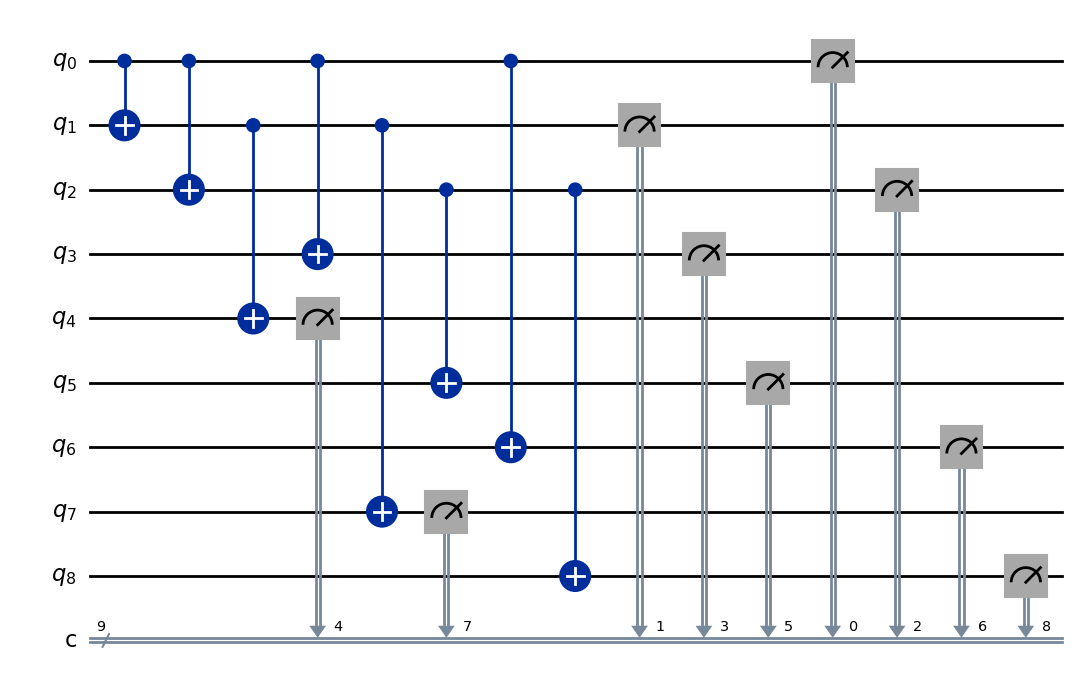

In [13]:
qc_shor.draw(output='mpl')

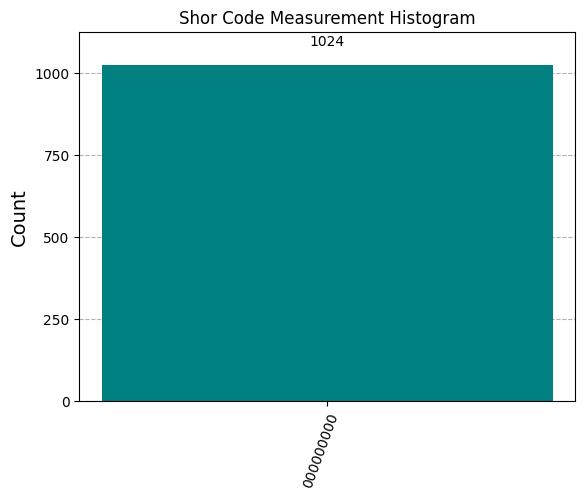

In [31]:
# Plot a histogram of measurement outcomes
plot_histogram(counts_shor, color='teal', title="Shor Code Measurement Histogram")

<!-- 2 -->
<div style="background-color:#e6ffe6; color:#006600; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">2. Steane Code</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> A 7-qubit code that corrects arbitrary single-qubit errors using stabilizer formalism.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: More efficient than Shor code; part of many fault-tolerant protocols.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: More complex syndrome extraction than repetition codes.</p>


In [40]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Steane Encoding: 7-qubit conceptual code
qc_steane = QuantumCircuit(7, 7)
# For simplicity, we begin by preparing a superposition on qubits 0,1,2.
qc_steane.h(0)
qc_steane.h(1)
qc_steane.h(2)

# Use CNOTs to entangle qubits based on the Hamming(7,4) structure.
qc_steane.cx(0, 3)
qc_steane.cx(1, 3)
qc_steane.cx(0, 4)
qc_steane.cx(2, 4)
qc_steane.cx(1, 5)
qc_steane.cx(2, 5)
qc_steane.cx(0, 6)
qc_steane.cx(1, 6)
qc_steane.cx(2, 6)

# Add measurements.
qc_steane.measure(range(7), range(7))

# Simulate with qasm simulator.
backend = Aer.get_backend('qasm_simulator')
tqc_steane = transpile(qc_steane, backend)
job_steane = backend.run(tqc_steane, shots=1024)
counts_steane = job_steane.result().get_counts()




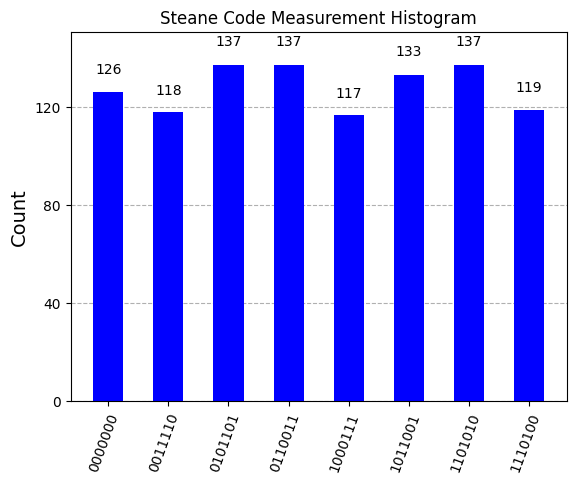

In [30]:
plot_histogram(counts_steane,color='blue', title="Steane Code Measurement Histogram")

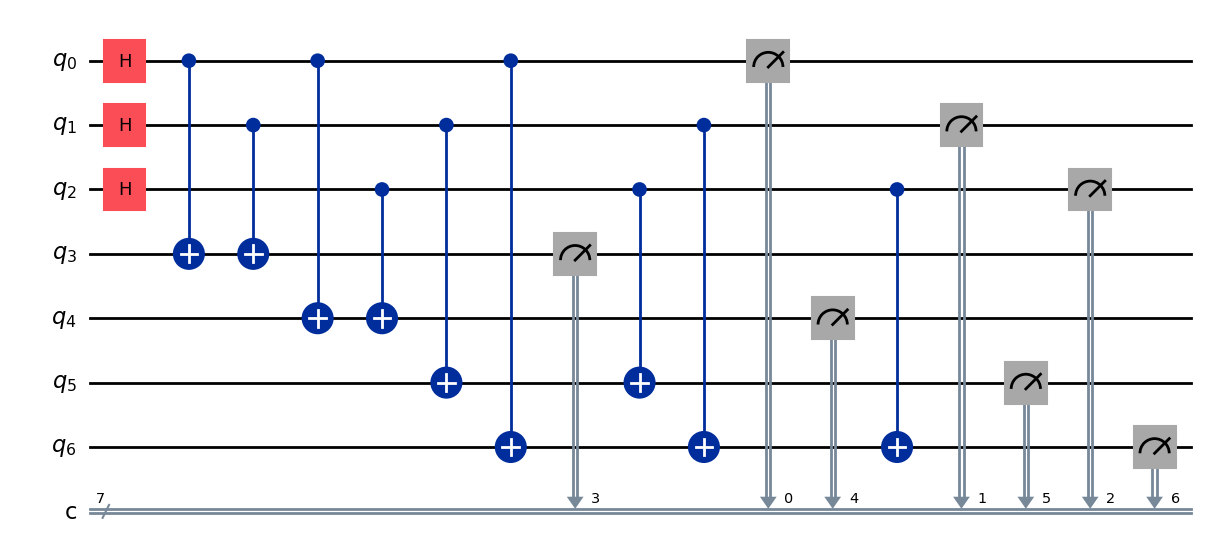

In [16]:
qc_steane.draw(output='mpl')

<!-- 3 -->
<div style="background-color:#e6f0ff; color:#003366; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">3. Calderbank-Shor-Steane (CSS) Code</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> Combines classical linear error-correcting codes to correct both bit and phase errors.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Supports fault-tolerant operations and scalable implementations.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Requires dual classical codes with special properties.</p>


In [17]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# CSS Code: 7-qubit conceptual circuit (illustrative pattern)
qc_css = QuantumCircuit(7, 7)
# Start with the logical qubit in qubit 0
qc_css.h(0)
# Spread the information using a series of CNOTs (conceptual parity-check pattern)
qc_css.cx(0, 1)
qc_css.cx(0, 2)
qc_css.cx(0, 4)
qc_css.cx(1, 3)
qc_css.cx(2, 5)
qc_css.cx(4, 6)

# Add measurements.
qc_css.measure(range(7), range(7))

backend = Aer.get_backend('qasm_simulator')
tqc_css = transpile(qc_css, backend)
job_css = backend.run(tqc_css, shots=1024)
counts_css = job_css.result().get_counts()




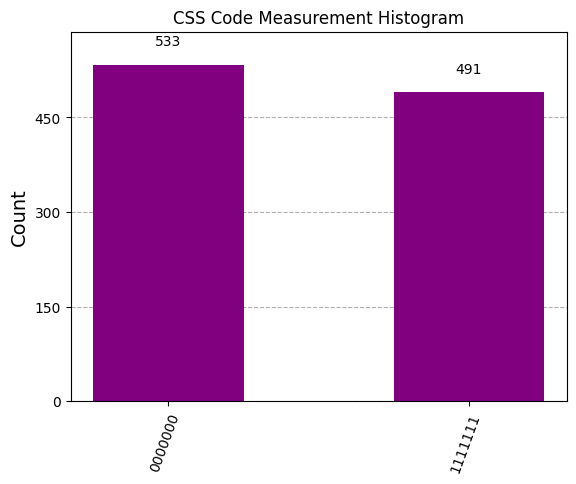

In [29]:
plot_histogram(counts_css,color='purple', title="CSS Code Measurement Histogram")

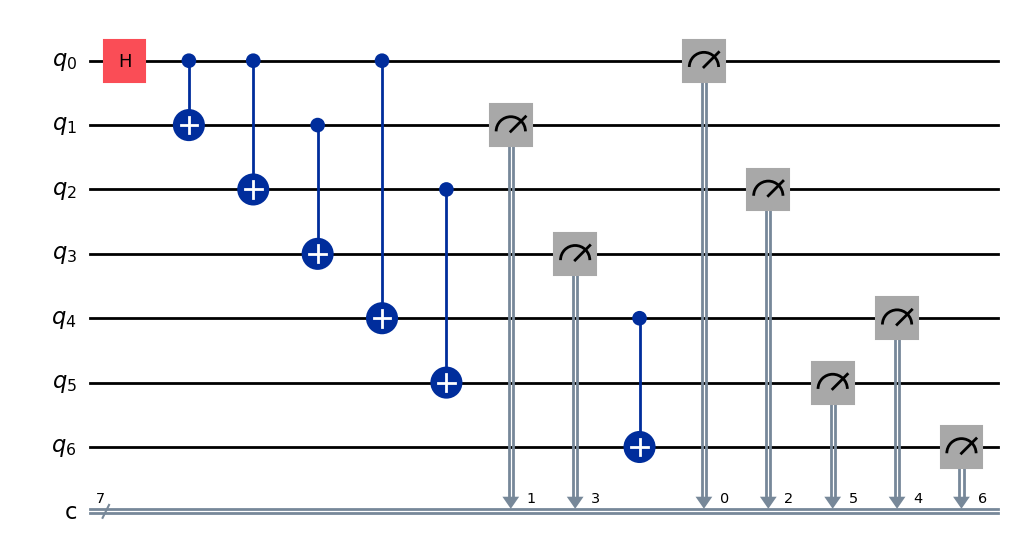

In [19]:
qc_css.draw(output='mpl')

<!-- 4 -->
<div style="background-color:#ffffcc; color:#666600; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">4. Toric Code</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> A topological code designed for 2D lattices with local stabilizer checks.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Naturally fault-tolerant; suitable for surface code implementations.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Needs large 2D qubit lattices and boundary management.</p>


In [20]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Toric Code: Conceptual 9-qubit circuit on a 3x3 lattice.
qc_toric = QuantumCircuit(9, 9)
# Initialize qubits in superposition.
for i in range(9):
    qc_toric.h(i)

# Apply some CNOTs between neighboring qubits to mimic stabilizer interactions.
qc_toric.cx(0, 1)
qc_toric.cx(1, 2)
qc_toric.cx(3, 4)
qc_toric.cx(4, 5)
qc_toric.cx(6, 7)
qc_toric.cx(7, 8)

# Add measurements.
qc_toric.measure(range(9), range(9))


backend = Aer.get_backend('qasm_simulator')
tqc_toric = transpile(qc_toric, backend)
job_toric = backend.run(tqc_toric, shots=1024)
counts_toric = job_toric.result().get_counts()



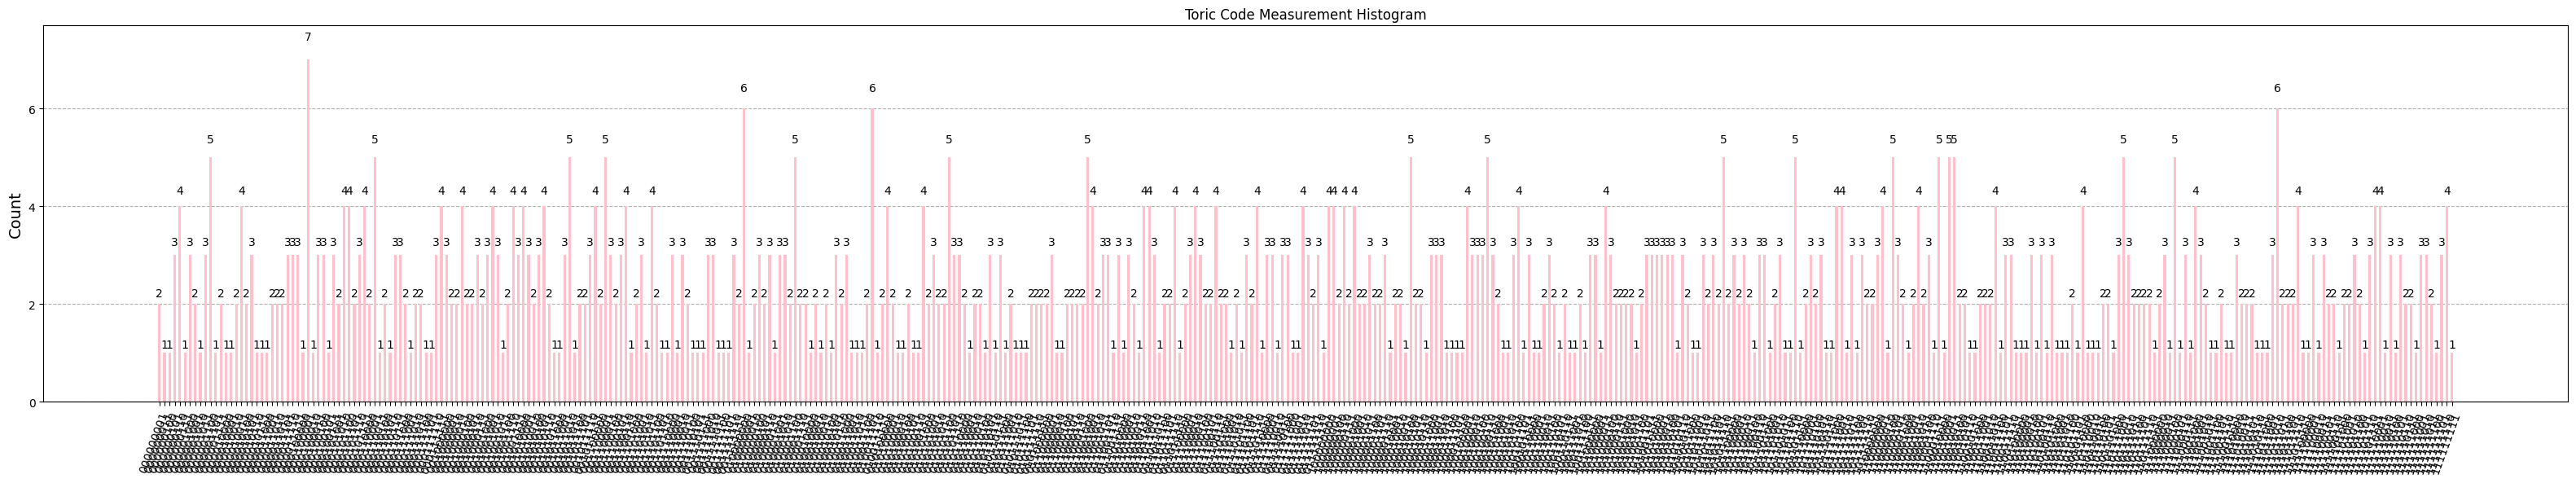

In [39]:
# Plot the Toric Code histogram with a single color ('pink') and adjusted figure size.
plot_histogram(counts_toric, color='pink', title="Toric Code Measurement Histogram", figsize=(40,6))

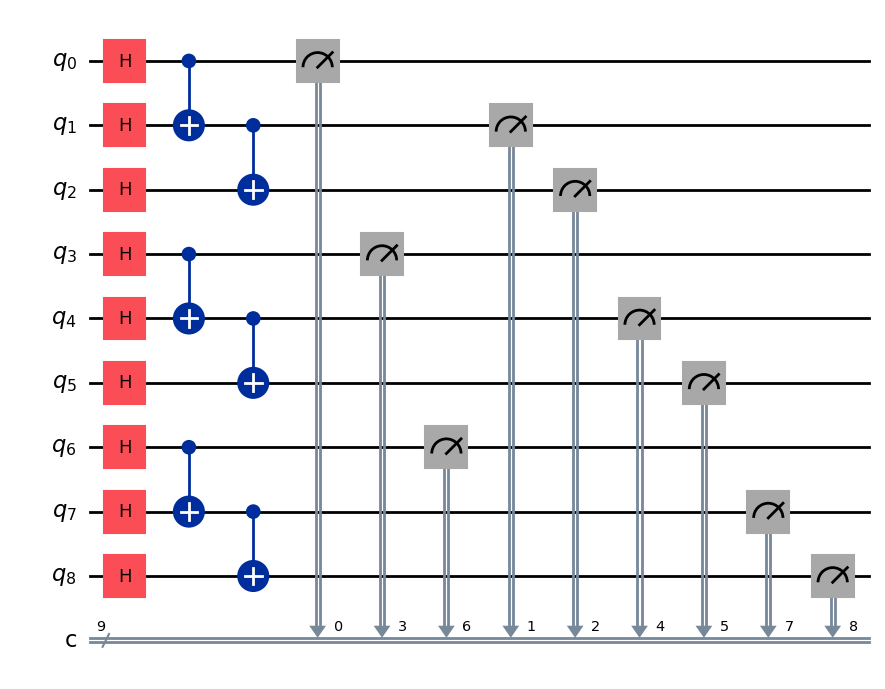

In [22]:

qc_toric.draw(output='mpl')

<!-- 5 -->
<div style="background-color:#ffebcc; color:#cc6600; padding:10px; font-weight:bold; font-size:20px; border-radius:8px;">5. Bacon-Shor Code</div>
<p style="margin-left:20px; font-size:20px;"><b style="color:#cc0000;">Motivation:</b> A subsystem code combining repetition codes in two dimensions.</p>
<p style="margin-left:20px; color:#006400; font-size:20px;">✓ Advantage: Easier syndrome measurement; fewer ancilla requirements.</p>
<p style="margin-left:20px; color:#8b0000; font-size:20px;">✗ Limitation: Still has higher qubit overhead compared to more recent surface codes.</p>

In [23]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt
from matplotlib import cm

# Bacon-Shor Code: Conceptual 4-qubit circuit.
qc_bacon_shor = QuantumCircuit(4, 4)
qc_bacon_shor.h(0)
qc_bacon_shor.cx(0, 1)
qc_bacon_shor.h(2)
qc_bacon_shor.cx(2, 3)
qc_bacon_shor.cx(0, 2)

qc_bacon_shor.measure(range(4), range(4))

backend = Aer.get_backend('qasm_simulator')
tqc_bacon = transpile(qc_bacon_shor, backend)
job_bacon = backend.run(tqc_bacon, shots=1024)
counts_bacon = job_bacon.result().get_counts()


C:\Users\muroo\AppData\Local\Temp\ipykernel_20720\2044608036.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('magma', len(keys))


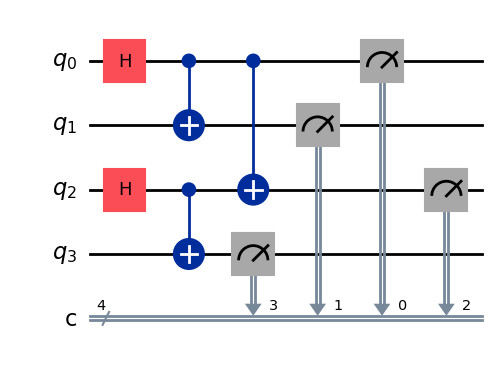

In [24]:
qc_bacon_shor.draw(output='mpl')

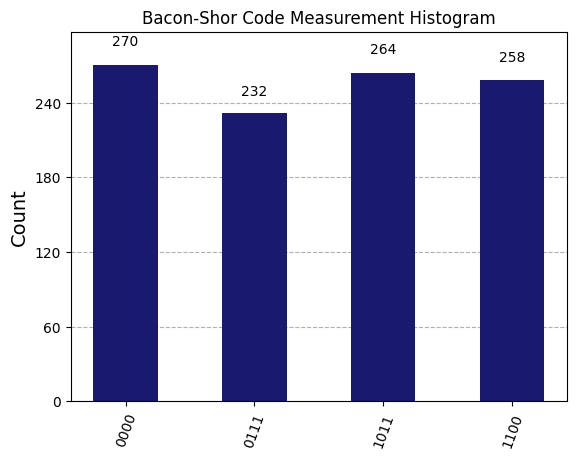

In [27]:
plot_histogram(counts_bacon, color='midnightblue', title="Bacon-Shor Code Measurement Histogram")